# Matched Expert / Unsmoothed spectra over a full month — Dask version

For every pass of a month the Unsmoothed file and the Expert file (stored in **separate directories**) are
paired on their `cycle_pass` numbers and processed with `process_matched_pair`. One worker = one pass.

Each worker writes its own small NetCDF (`<output>/<YYYY-MM>/per_pass/`), so

* a crash or a restart only redoes the missing passes (`SKIP_EXISTING`),
* the main process never holds the full month in memory,
* the per-pass files are merged lazily at the end (`open_mfdataset`) into one monthly file.

> **Requires the updated `swot_matched_spectra.py`** (row QC + `qc_ok` / `qc_reasons` flags) installed as
> `swot_analysis/swot_matched_spectra.py`.

## 1. Imports

In [1]:
import functools
import glob
import os
import re
import time
import traceback
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

import dask
from dask.distributed import Client, LocalCluster, progress, wait

## 2. Configuration

In [15]:
# ── Directories (Expert and Unsmoothed are separate) ─────────────────────────
EXPERT_DIR     = '/work/uo0122/u241387/SWOT_SSH/SSH_Expert/'       
UNSMOOTHED_DIR = '/work/uo0122/u241387/SWOT_SSH/SSH_Unsmoothed/'
OUTPUT_DIR     = '/work/uo0122/u241387/SWOT_SSH/diags_matched/'
SCRATCH_DIR    = '/scratch/u/u241387/'

# ── One entry per month: sub-directory of each product ───────────────────────
# (year, month) is read from the trailing MMYY of the Unsmoothed sub-directory name.
MONTHS = [
    dict(expert='SWOT_L2_LR_SSH_Expert_0124/',
         unsmoothed='SWOT_L2_LR_SSH_Unsmoothed_0124/'),
    # dict(expert='SWOT_L2_LR_SSH_Expert_0224/', unsmoothed='SWOT_L2_LR_SSH_Unsmoothed_0224/'),
]
EXPERT_PATTERN     = 'SWOT_L2_LR_SSH_Expert_*.nc'
UNSMOOTHED_PATTERN = 'SWOT_L2_LR_SSH_Unsmoothed_*.nc'
MAX_FILES_PER_MONTH = None        # e.g. 10 for a quick test, None = all
SKIP_EXISTING       = True        # reuse per-pass files already written

# ── Spectral parameters (passed to process_matched_pair) ─────────────────────
SEGMENT_LENGTH_KM = 1000.0
OVERLAP           = 0.5
MAX_NAN_FRACTION  = 0.15
MAX_GAP_FRACTION  = 0.1
N_TAPS            = 17
DETREND           = 'plane'       # "plane" | "linear" | "constant" | None
REMOVE_EDGES_KM   = 5
DX1_NATIVE_KM = DX2_NATIVE_KM = 0.25
DX1_EXPERT_KM = DX2_EXPERT_KM = 2.0

# ── Region of interest ───────────────────────────────────────────────────────
LAT_MIN, LAT_MAX = -60.0, 60.0
LON_MIN, LON_MAX = 0.0, 360.0

# ── Variables ────────────────────────────────────────────────────────────────
SSH_VAR = 'ssha_karin_2'
HRET    = False

# ── QC (see swot_matched_spectra.py). Flagged pairs are kept with qc_ok=False
#    unless drop_flagged=True. Add any qc_* argument here to override defaults.
QC_KWARGS = dict(drop_flagged=False)

# ── Box averaging (last section) ─────────────────────────────────────────────
BOX_DEG = 2.0
MIN_SAMPLING_FRACTION = 0.
BOX_METHOD = 'mean'               # 'mean' | 'median' | 'log'

# ── Dask ─────────────────────────────────────────────────────────────────────
N_WORKERS          = 3
THREADS_PER_WORKER = 1            # keep 1: HDF5/netCDF4 is not thread-safe
MEMORY_LIMIT       = '6GB'       # per worker. One pass is several GB at peak
                                  # (full-resolution 250 m arrays + copies): if workers
                                  # get killed, lower N_WORKERS or raise this.

## 3. Start the Dask cluster
`threads_per_worker=1`: the spectral loops are GIL-bound and netCDF4/HDF5 is not thread-safe within a process.

In [3]:
dask.config.config.get('distributed').get('dashboard').update(
    {'link': '{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'}
)
cluster = LocalCluster(n_workers=N_WORKERS, threads_per_worker=THREADS_PER_WORKER,
                       memory_limit=MEMORY_LIMIT, dashboard_address=':8787')
client = Client(cluster)
print(f'Dashboard: {client.dashboard_link}')
client

Dashboard: /user/u241387/levante-spawner-preset//proxy/8787/status


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/u241387/levante-spawner-preset//proxy/8787/status,
Dashboard: /user/u241387/levante-spawner-preset//proxy/8787/status,Workers: 3
Total threads: 3,Total memory: 16.76 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35981,Workers: 0
Dashboard: /user/u241387/levante-spawner-preset//proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34049,Total threads: 1
Dashboard: /user/u241387/levante-spawner-preset//proxy/36679/status,Memory: 5.59 GiB
Nanny: tcp://127.0.0.1:37715,


## 4. Pair Expert and Unsmoothed files
Files are matched on the `cycle_pass` numbers in their names (e.g. `..._013_344_...`).
If a pass has several versions of a file, the last one in sorted order is used (with a warning).
Passes that exist in only one product are listed and skipped.

In [16]:
_KEY_RE = re.compile(r'_(\d{3})_(\d{3})_')

def parse_year_month(subdir_name):
    """Trailing MMYY of a sub-directory name -> (year, month)."""
    m = re.search(r'(\d{2})(\d{2})/?$', subdir_name.rstrip('/\\') )
    if not m:
        raise ValueError(f"Cannot infer month/year from '{subdir_name}'")
    month, year = int(m.group(1)), 2000 + int(m.group(2))
    if not 1 <= month <= 12:
        raise ValueError(f"Invalid month {month} in '{subdir_name}'")
    return year, month

def pass_key(path):
    """(cycle, pass) parsed from a SWOT file name."""
    m = _KEY_RE.search(Path(path).name)
    if not m:
        raise ValueError(f'No cycle/pass number in file name: {path}')
    return int(m.group(1)), int(m.group(2))

def index_by_pass(files, label):
    out = {}
    for f in sorted(files):
        k = pass_key(f)
        if k in out:
            warnings.warn(f'{label}: several files for cycle/pass {k}; using {Path(f).name}')
        out[k] = f
    return out

jobs, unmatched = [], []
for m in MONTHS:
    year, month = parse_year_month(m['unsmoothed'])
    exp  = index_by_pass(glob.glob(os.path.join(EXPERT_DIR, m['expert'], EXPERT_PATTERN)), 'Expert')
    uns  = index_by_pass(glob.glob(os.path.join(UNSMOOTHED_DIR, m['unsmoothed'], UNSMOOTHED_PATTERN)), 'Unsmoothed')
    common = sorted(set(exp) & set(uns))
    if MAX_FILES_PER_MONTH:
        common = common[:MAX_FILES_PER_MONTH]
    only_e, only_u = sorted(set(exp) - set(uns)), sorted(set(uns) - set(exp))
    unmatched.append((year, month, only_e, only_u))
    out_dir = os.path.join(OUTPUT_DIR, f'{year}-{month:02d}', 'per_pass')
    os.makedirs(out_dir, exist_ok=True)
    for key in common:
        jobs.append(dict(key=key, year=year, month=month,
                         unsmoothed=uns[key], expert=exp[key],
                         out=os.path.join(out_dir, f'matched_{key[0]:03d}_{key[1]:03d}.nc')))
    print(f'{year}-{month:02d}: {len(exp)} Expert, {len(uns)} Unsmoothed, '
          f'{len(common)} matched | only Expert: {len(only_e)}, only Unsmoothed: {len(only_u)}')

print(f'\n{len(jobs)} passes to process.')

2024-01: 865 Expert, 865 Unsmoothed, 865 matched | only Expert: 0, only Unsmoothed: 0

865 passes to process.


## 5. Worker function
Runs in a worker process: loads one pass of each product, computes the matched spectra, writes a NetCDF.
Errors are returned (with traceback) instead of raised, so one bad pass never cancels the month.
The file is written under a temporary name and renamed, so an interrupted run never leaves a half-written file.

In [5]:
def process_one_pass(job, ssh_var, hret, pair_kwargs, skip_existing):
    import os, traceback, warnings
    import numpy as np
    from swot_analysis.swot_matched_spectra import (
        process_matched_pair, flatten_matched_pairs, matched_pairs_to_dataset)

    warnings.filterwarnings('ignore', category=RuntimeWarning)   # all-NaN slice etc.
    key, out = job['key'], job['out']
    summary = dict(cycle=key[0], pass_number=key[1], year=job['year'], month=job['month'],
                   file=out, status=None, n_pairs=0, n_flagged=0, error=None)

    if skip_existing and os.path.exists(out):
        summary['status'] = 'existing'
        return summary

    try:
        result, counts = process_matched_pair(
            job['unsmoothed'], job['expert'], output_path=None,
            ssh_var=ssh_var, hret=hret, return_counts=True, verbose=False,
            **pair_kwargs)
    except Exception:
        summary.update(status='error', error=traceback.format_exc())
        return summary

    for sw in ('left', 'right'):
        c = counts[sw]
        summary[f'{sw}_pairs'] = c['n_pairs']
        summary[f'{sw}_unsmoothed_used'] = c['n_unsmoothed_used']
        summary[f'{sw}_flagged'] = c.get('n_flagged_qc', 0)
        summary[f'{sw}_no_expert_match'] = c['n_dropped_no_expert_match']
        summary[f'{sw}_dx_unsmoothed_km'] = c.get('dx_actual_km', {}).get('unsmoothed', np.nan)
        summary[f'{sw}_dx_expert_km'] = c.get('dx_actual_km', {}).get('expert', np.nan)
    flat = flatten_matched_pairs(result)
    summary['n_pairs'] = len(flat)
    summary['n_flagged'] = int(sum(not p.qc_ok for p in flat))

    if not flat:
        summary['status'] = 'empty'
        return summary

    try:
        n = len(flat)
        ds = matched_pairs_to_dataset(flat)
        ds = ds.assign(
            cycle=('segment', np.full(n, key[0])),
            pass_number=('segment', np.full(n, key[1])),
            year=('segment', np.full(n, job['year'])),
            month=('segment', np.full(n, job['month'])),
        )
        tmp = out + '.tmp'
        ds.to_netcdf(tmp, mode='w')
        os.replace(tmp, out)
        summary['status'] = 'ok'
    except Exception:
        summary.update(status='error', error=traceback.format_exc())
    return summary

## 6. Run in parallel
`client.map` sends one pass per task. Watch the *Task Stream* and *Workers* tabs in the dashboard
(memory per worker is the thing to keep an eye on).

In [ ]:
pair_kwargs = dict(
    segment_length_km=SEGMENT_LENGTH_KM, overlap=OVERLAP,
    max_nan_fraction=MAX_NAN_FRACTION, max_gap_fraction=MAX_GAP_FRACTION,
    n_taps=N_TAPS, detrend=DETREND, remove_edges_km=REMOVE_EDGES_KM,
    dx1_native_km=DX1_NATIVE_KM, dx2_native_km=DX2_NATIVE_KM,
    dx1_expert_km=DX1_EXPERT_KM, dx2_expert_km=DX2_EXPERT_KM,
    lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX,
    **QC_KWARGS,
)
worker_fn = functools.partial(process_one_pass, ssh_var=SSH_VAR, hret=HRET,
                              pair_kwargs=pair_kwargs, skip_existing=SKIP_EXISTING)

t0 = time.time()
futures = client.map(worker_fn, jobs, pure=False)
progress(futures)
wait(futures)
print(f'\nElapsed: {(time.time() - t0) / 60:.1f} min')

In [7]:
summaries = client.gather(futures, errors='skip')
df = pd.DataFrame(summaries)
print(df['status'].value_counts().to_string())
print(f"\nPairs: {int(df['n_pairs'].sum())}  |  flagged (qc_ok=False): {int(df['n_flagged'].sum())}")

failed = df[df['status'] == 'error']
for _, r in failed.iterrows():
    print(f"\n--- cycle {r.cycle:03d} pass {r.pass_number:03d} ---\n{r.error}")

if len(summaries) < len(jobs):
    print(f'\n{len(jobs) - len(summaries)} task(s) lost (worker killed? likely out of memory) '
          f'-> lower N_WORKERS or raise MEMORY_LIMIT and rerun (SKIP_EXISTING resumes).')

status
ok       850
error     14
empty      2

Pairs: 28872  |  flagged (qc_ok=False): 2455

--- cycle 025 pass 092 ---
Traceback (most recent call last):
  File "/tmp/ipykernel_183366/4205399144.py", line 17, in process_one_pass
  File "/home/u/u241387/SWOT_UHH/swot_analysis/swot_matched_spectra.py", line 1119, in process_matched_pair
    result, counts = compute_matched_spectra(
                     ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/u/u241387/SWOT_UHH/swot_analysis/swot_matched_spectra.py", line 751, in compute_matched_spectra
    edge_u = _edge_in_xt_units(data_unsmoothed["cross_track_distance"], remove_edges_km)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/u/u241387/SWOT_UHH/swot_analysis/swot_matched_spectra.py", line 333, in _edge_in_xt_units
    if np.nanmax(np.abs(xt)) > 1000.0:  # values are metres
       ^^^^^^^^^^^^^^^^^^^^^
  File "/home/u/u241387/.conda/envs/swot_env/lib/python3.11/site-packages/numpy/lib/_nanf

## 7. Merge the per-pass files into one dataset per month
Opened lazily with `open_mfdataset` (dask arrays); nothing is loaded until the write.

In [17]:
def _prep(d):
    return d.drop_vars('segment', errors='ignore')

ds_months = {}
for year, month in sorted({(j['year'], j['month']) for j in jobs}):
    files = sorted(glob.glob(os.path.join(SCRATCH_DIR, f'{year}-{month:02d}', 'per_pass', 'matched_*.nc')))
    if not files:
        print(f'{year}-{month:02d}: no per-pass files'); continue
    ds_m = xr.open_mfdataset(files, combine='nested', concat_dim='segment', preprocess=_prep,
                             data_vars='minimal', coords='minimal', compat='override',
                             parallel=True)
    ds_m = ds_m.assign_coords(segment=np.arange(ds_m.sizes['segment']))
    ds_m.attrs.update(year=year, month=month, ssh_var=SSH_VAR, hret=int(HRET),
                      segment_length_km=SEGMENT_LENGTH_KM, detrend=str(DETREND))
    out_file = os.path.join(OUTPUT_DIR, f'matched_spectra_{year}-{month:02d}.nc')
    ds_m.to_netcdf(out_file, mode='w')
    ds_months[(year, month)] = out_file
    n_ok = int(ds_m['qc_ok'].sum())
    print(f"{year}-{month:02d}: {ds_m.sizes['segment']} segments from {len(files)} passes "
          f"({n_ok} with qc_ok) -> {out_file}")

/home/u/u241387/.conda/envs/swot_env/lib/python3.11/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 30.13 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


2024-01: 28874 segments from 850 passes (26412 with qc_ok) -> /work/uo0122/u241387/SWOT_SSH/diags_matched/matched_spectra_2024-01.nc


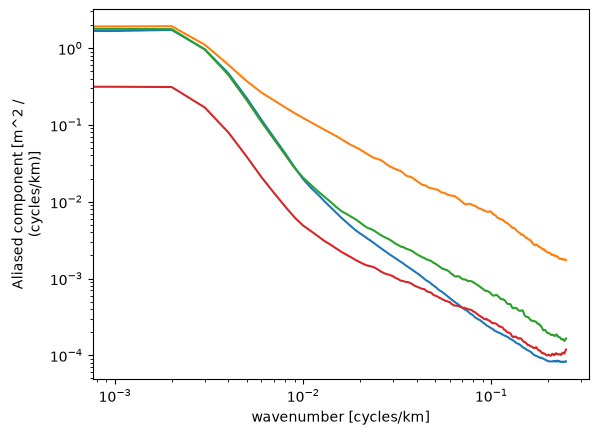

In [29]:
ds_m.mean('segment').expert_psd.plot(xscale='log',yscale='log')
ds_m.mean('segment').predicted_psd.plot(xscale='log',yscale='log')
ds_m.where(ds_m.qc_ok).mean('segment').predicted_psd.plot(xscale='log',yscale='log')
ds_m.where(ds_m.qc_ok).mean('segment').aliased_psd.plot(xscale='log',yscale='log')

## 8. Box-averaged spectra (optional)
Averages the `qc_ok` segments in `BOX_DEG` boxes, for each of the four spectra, on a regular (lat, lon) grid.

In [18]:
from collections import defaultdict

def build_box_dataset(ds_segments, box_deg=2.0, method='mean',
                      min_sampling_fraction=0.5, var='psd'):
    """Gridded (lat, lon, wavenumber) box average; lat/lon are box centres."""
    if method not in ('mean', 'median', 'log'):
        raise ValueError(f"method must be 'mean', 'median' or 'log', got {method!r}")
    lat = ds_segments['lat_mean'].values
    lon = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)
    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)

    psd_all = ds_segments[var].values
    wavenumber = ds_segments['wavenumber'].values
    li_axis = np.arange(lat_idx.min(), lat_idx.max() + 1)
    lo_axis = np.arange(lon_idx.min(), lon_idx.max() + 1)
    n_max = max(len(v) for v in box_to_segs.values())
    psd_grid = np.full((li_axis.size, lo_axis.size, wavenumber.size), np.nan)
    n_grid = np.zeros((li_axis.size, lo_axis.size), dtype=int)

    for (li, loi), idxs in box_to_segs.items():
        if len(idxs) < min_sampling_fraction * n_max:
            continue
        sub = psd_all[idxs, :]
        if method == 'mean':
            p = np.nanmean(sub, axis=0)
        elif method == 'median':
            p = np.nanmedian(sub, axis=0)
        else:
            with np.errstate(divide='ignore', invalid='ignore'):
                p = np.exp(np.nanmean(np.log(sub), axis=0))
        psd_grid[li - li_axis[0], loi - lo_axis[0]] = p
        n_grid[li - li_axis[0], loi - lo_axis[0]] = len(idxs)

    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['lat', 'lon', 'wavenumber'], psd_grid,
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['lat', 'lon'], n_grid),
            sampling_fraction=(['lat', 'lon'], n_grid / n_max),
        ),
        coords=dict(
            lat=('lat', (li_axis + 0.5) * box_deg, {'units': 'degrees_north'}),
            lon=('lon', (lo_axis + 0.5) * box_deg, {'units': 'degrees_east'}),
            wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        ),
        attrs=dict(box_size_deg=box_deg, min_sampling_fraction=min_sampling_fraction),
    )


def box_all_spectra(ds_segments, **kw):
    """Box-average expert/predicted/direct/aliased PSD of the qc_ok segments."""
    ok = np.where(ds_segments['qc_ok'].values)[0]
    if ok.size == 0:
        raise ValueError('No segment with qc_ok=True.')
    ds_ok = ds_segments.isel(segment=ok).load()
    parts = {v: build_box_dataset(ds_ok, var=v, **kw)
             for v in ('expert_psd', 'predicted_psd', 'direct_psd', 'aliased_psd')}
    out = xr.Dataset({v: p['mean_psd'] for v, p in parts.items()})
    out['n_segments'] = parts['expert_psd']['n_segments']
    out['sampling_fraction'] = parts['expert_psd']['sampling_fraction']
    out.attrs.update(parts['expert_psd'].attrs, n_segments_ok=int(ok.size))
    return out


ds_boxes = {}
for (year, month), f in ds_months.items():
    with xr.open_dataset(f) as ds_m:
        ds_boxes[(year, month)] = box_all_spectra(
            ds_m, box_deg=BOX_DEG, method=BOX_METHOD,
            min_sampling_fraction=MIN_SAMPLING_FRACTION)
    out_file = os.path.join(OUTPUT_DIR, f'matched_boxes_{BOX_DEG:g}deg_{year}-{month:02d}.nc')
    ds_boxes[(year, month)].to_netcdf(out_file, mode='w')
    print(f'{year}-{month:02d}: {int((ds_boxes[(year, month)].n_segments > 0).sum())} boxes -> {out_file}')

2024-01: 6720 boxes -> /work/uo0122/u241387/SWOT_SSH/diags_matched/matched_boxes_2deg_2024-01.nc


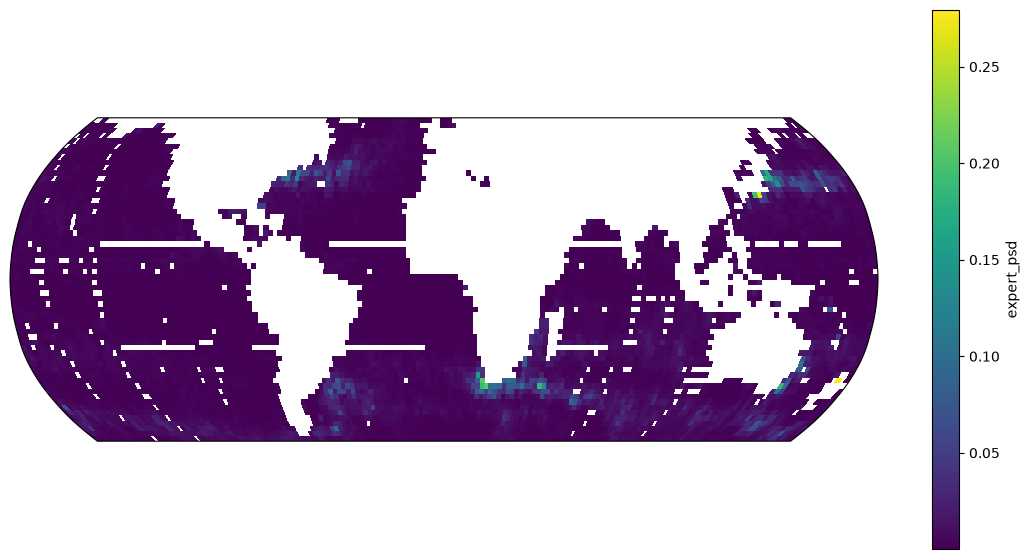

In [19]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
energy = ds_boxes[(year, month)].expert_psd.integrate('wavenumber')
fig,ax = plt.subplots(figsize=(14,7),subplot_kw={"projection": ccrs.Robinson()})
energy.plot(ax=ax,transform=ccrs.PlateCarree())

## 9.Merge full year

In [20]:
YEAR = 2024
BUILD_YEAR_BOXES = True   # box-average the full year of segments (uses box_all_spectra from section 8)

files = sorted(glob.glob(os.path.join(OUTPUT_DIR, f'matched_spectra_{YEAR}-??.nc')))
months_found = sorted(int(re.search(r'-(\d{2})\.nc$', f).group(1)) for f in files)
missing = sorted(set(range(1, 13)) - set(months_found))
print(f'{YEAR}: {len(files)} monthly files, months {months_found}')
if missing:
    print(f'WARNING: missing months {missing} -> the yearly dataset will be incomplete')
if not files:
    raise FileNotFoundError(f'No monthly files for {YEAR} in {OUTPUT_DIR}')

ds_year = xr.open_mfdataset(files, combine='nested', concat_dim='segment',
                            preprocess=lambda d: d.drop_vars('segment', errors='ignore'),
                            data_vars='minimal', coords='minimal', compat='override',
                            parallel=False)      # serial open: HDF5 is not thread-safe
ds_year = ds_year.assign_coords(segment=np.arange(ds_year.sizes['segment']))
ds_year.attrs = {k: v for k, v in ds_year.attrs.items() if k != 'month'}
ds_year.attrs.update(year=YEAR, months=','.join(f'{m:02d}' for m in months_found))

out_year = os.path.join(OUTPUT_DIR, f'matched_spectra_{YEAR}.nc')
tmp = out_year + '.tmp'
ds_year.to_netcdf(tmp, mode='w')
os.replace(tmp, out_year)

with xr.open_dataset(out_year) as chk:
    n_ok = int(chk['qc_ok'].sum())
    print(f"-> {out_year}: {chk.sizes['segment']} segments ({n_ok} with qc_ok, "
          f"{chk.sizes['segment'] - n_ok} flagged)")
    print('segments per month:', {int(m): int((chk['month'] == m).sum()) for m in np.unique(chk['month'])})

if BUILD_YEAR_BOXES:
    with xr.open_dataset(out_year) as chk:
        ds_boxes_year = box_all_spectra(chk, box_deg=BOX_DEG, method=BOX_METHOD,
                                        min_sampling_fraction=MIN_SAMPLING_FRACTION)
    out_boxes = os.path.join(OUTPUT_DIR, f'matched_boxes_{BOX_DEG:g}deg_{YEAR}.nc')
    ds_boxes_year.to_netcdf(out_boxes, mode='w')
    print(f"-> {out_boxes}: {int((ds_boxes_year.n_segments > 0).sum())} boxes")

2024: 12 monthly files, months [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


HDF5-DIAG: Error detected in HDF5 (1.14.6) thread 1:
  #000: H5F.c line 496 in H5Fis_accessible(): unable to determine if file is accessible as HDF5
    major: File accessibility
    minor: Not an HDF5 file
  #001: H5VLcallback.c line 3913 in H5VL_file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #002: H5VLcallback.c line 3848 in H5VL__file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #003: H5VLnative_file.c line 344 in H5VL__native_file_specific(): error in HDF5 file check
    major: File accessibility
    minor: Can't get value
  #004: H5Fint.c line 1055 in H5F__is_hdf5(): unable to open file
    major: File accessibility
    minor: Unable to initialize object
  #005: H5FD.c line 787 in H5FD_open(): can't open file
    major: Virtual File Layer
    minor: Unable to open file
  #006: H5FDsec2.c line 323 in H5FD__sec2_open(): unable to open file: name = '/work/uo0122/u24138

-> /work/uo0122/u241387/SWOT_SSH/diags_matched/matched_spectra_2024.nc: 343731 segments (314550 with qc_ok, 29181 flagged)
segments per month: {1: 28874, 2: 27744, 3: 29649, 4: 28982, 5: 28339, 6: 28418, 7: 29194, 8: 29272, 9: 27507, 10: 28540, 11: 28340, 12: 28872}
-> /work/uo0122/u241387/SWOT_SSH/diags_matched/matched_boxes_2deg_2024.nc: 7054 boxes


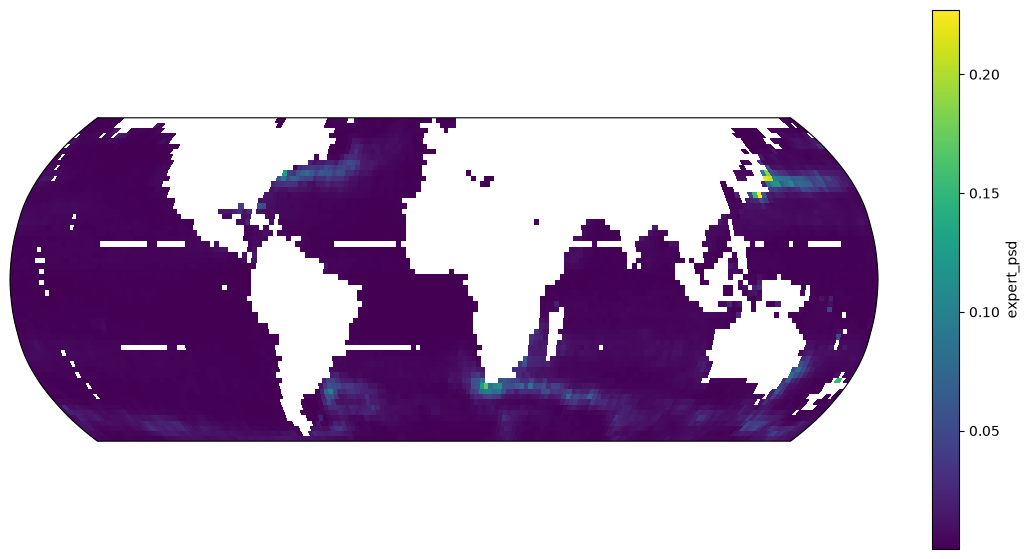

In [21]:
energy = ds_boxes_year.expert_psd.integrate('wavenumber')
fig,ax = plt.subplots(figsize=(14,7),subplot_kw={"projection": ccrs.Robinson()})
energy.plot(ax=ax,transform=ccrs.PlateCarree())

## 10. Shut down

In [22]:
client.close()
cluster.close()